In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG19, MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.callbacks import EarlyStopping
from google.colab import files
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

In [2]:
import os
import zipfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import imutils
import time
import pandas as pd

In [3]:
uploaded = files.upload()

Saving cell_images.zip to cell_images.zip


In [4]:
!unzip -o cell_images.zip -d /content/cell_images

Streaming output truncated to the last 5000 lines.
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_116.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_118.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_126.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_134.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_141.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_168.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_175.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_183.png  
  inflating: /content/cell_images/cell_images/Uninfected/C236ThinF_IMG_20151127_102428_cell_221.png  
  inflating: /content/cell_imag

In [5]:
zip_file_name = list(uploaded.keys())[0]
zip_file_name

'cell_images.zip'

In [6]:
EXTRACT_DIR = "./malaria_dataset"
print(f"Extracting {zip_file_name} to {EXTRACT_DIR}...")
with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)
print("Extraction complete!")


Extracting cell_images.zip to ./malaria_dataset...
Extraction complete!


In [7]:
subfolders = os.listdir(EXTRACT_DIR)
print("Detected contents:", subfolders)

Detected contents: ['cell_images']


In [8]:
if len(subfolders) == 1 and os.path.isdir(os.path.join(EXTRACT_DIR, subfolders[0])):
    DATA_DIR = os.path.join(EXTRACT_DIR, subfolders[0])
else:
    DATA_DIR = EXTRACT_DIR

In [9]:
print(os.listdir('/content/cell_images'))

['cell_images']


In [10]:
dataset_path = '/content/malaria_dataset/cell_images/cell_images'

In [11]:
dataset_path = '/content/cell_images/cell_images'
df=[]
for label in os.listdir(dataset_path):
    folder = os.path.join(dataset_path, label)

    if os.path.isdir(folder):
        count = len([
            f for f in os.listdir(folder)
            if f.endswith('.png')
        ])

        df.append({
            'Class': label,
            'Count': count
        })

In [12]:
dt=pd.DataFrame(df)

In [13]:
dt

,Class,Count
0,Parasitized,13779
1,Uninfected,13779


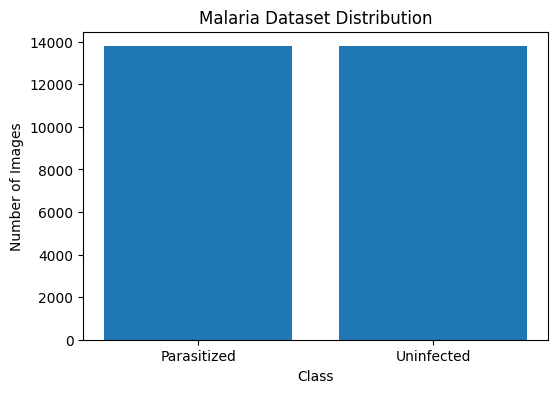

In [14]:
plt.figure(figsize=(6,4))

plt.bar(dt['Class'], dt['Count'])

plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.title('Malaria Dataset Distribution')

plt.show()

In [15]:
IMG_SIZE = (124, 124)
BATCH_SIZE = 32

In [16]:
datagen = ImageDataGenerator(rescale=1./255,validation_split=0.2,rotation_range=20,width_shift_range=0.1,height_shift_range=0.1,horizontal_flip=True,vertical_flip=True)

train_generator = datagen.flow_from_directory(DATA_DIR,target_size=IMG_SIZE,batch_size=BATCH_SIZE,class_mode='binary',subset='training',shuffle=True)

val_generator = datagen.flow_from_directory(DATA_DIR,target_size=IMG_SIZE,batch_size=BATCH_SIZE,class_mode='binary',subset='validation',shuffle=False)

Found 22048 images belonging to 2 classes.
Found 5510 images belonging to 2 classes.


In [17]:
def build_vgg19(input_shape):
    base_model = VGG19(weights='imagenet', include_top=False, input_shape=input_shape)
    for layer in base_model.layers:
        layer.trainable = False

    x = Flatten()(base_model.output)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    output = Dense(1, activation='sigmoid')(x)

    return Model(inputs=base_model.input, outputs=output, name="Malaria_VGG19")

In [18]:
def build_mobilenet(input_shape):
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
    for layer in base_model.layers:
        layer.trainable = False

    x = GlobalAveragePooling2D()(base_model.output)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    output = Dense(1, activation='sigmoid')(x)

    return Model(inputs=base_model.input, outputs=output, name="Malaria_MobileNetV2")

In [19]:
input_shape = (IMG_SIZE[0], IMG_SIZE[1], 3)
epochs = 10

In [20]:
vgg19_model = build_vgg19(input_shape)
vgg19_model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [21]:
print("\n--- Training VGG19 ---")
vgg19_history = vgg19_model.fit(train_generator, validation_data=val_generator, epochs=epochs)


--- Training VGG19 ---
Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 165s 225ms/step - accuracy: 0.8316 - loss: 0.3786 - val_accuracy: 0.8559 - val_loss: 0.3211
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 154s 224ms/step - accuracy: 0.8787 - loss: 0.2902 - val_accuracy: 0.8880 - val_loss: 0.2774
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 155s 226ms/step - accuracy: 0.8923 - loss: 0.2663 - val_accuracy: 0.8869 - val_loss: 0.2668
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 152s 221ms/step - accuracy: 0.9000 - loss: 0.2516 - val_accuracy: 0.8915 - val_loss: 0.2639
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 153s 222ms/step - accuracy: 0.8992 - loss: 0.2511 - val_accuracy: 0.8917 - val_loss: 0.2589
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 152s 220ms/step - accuracy: 0.9020 - loss: 0.2437 - val_accuracy: 0.9036 - val_loss: 0.2468
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 153s 222ms/step - accuracy: 0.9057 - loss: 0.2393 - val_accuracy: 0.9000 - val_loss: 0.2481
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 152s 221ms/s

In [22]:
test_loss, test_acc = vgg19_model.evaluate(val_generator)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

173/173 ━━━━━━━━━━━━━━━━━━━━ 32s 186ms/step - accuracy: 0.9005 - loss: 0.2370
Test Loss: 0.23696118593215942
Test Accuracy: 0.9005444645881653


In [ ]:
base_model = tf.keras.applications.VGG19(weights='imagenet',include_top=False,input_shape=(224, 224, 3))

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)

history = vgg19_model.fit(train_generator,validation_data=val_generator,epochs=12,callbacks=[early_stopping])

Epoch 1/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 156s 227ms/step - accuracy: 0.9130 - loss: 0.2206 - val_accuracy: 0.9056 - val_loss: 0.2276
Epoch 2/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 154s 224ms/step - accuracy: 0.9125 - loss: 0.2200 - val_accuracy: 0.9073 - val_loss: 0.2247
Epoch 3/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 156s 227ms/step - accuracy: 0.9136 - loss: 0.2207 - val_accuracy: 0.9056 - val_loss: 0.2209
Epoch 4/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 157s 228ms/step - accuracy: 0.9147 - loss: 0.2167 - val_accuracy: 0.9049 - val_loss: 0.2273
Epoch 5/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 157s 228ms/step - accuracy: 0.9152 - loss: 0.2131 - val_accuracy: 0.9136 - val_loss: 0.2190
Epoch 6/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 167s 242ms/step - accuracy: 0.9154 - loss: 0.2146 - val_accuracy: 0.9083 - val_loss: 0.2167
Epoch 7/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 168s 244ms/step - accuracy: 0.9155 - loss: 0.2125 - val_accuracy: 0.9131 - val_loss: 0.2154
Epoch 8/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 157s 228ms/step - accuracy: 0.9161 -

In [ ]:
mobilenet_model = build_mobilenet(input_shape)
mobilenet_model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

/tmp/ipykernel_782/4186385797.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)


In [ ]:
mobilenet_history = mobilenet_model.fit(train_generator, validation_data=val_generator, epochs=epochs)

Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 173s 226ms/step - accuracy: 0.8897 - loss: 0.2704 - val_accuracy: 0.9140 - val_loss: 0.2246
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 140s 203ms/step - accuracy: 0.9236 - loss: 0.2040 - val_accuracy: 0.9172 - val_loss: 0.2105
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 149s 217ms/step - accuracy: 0.9306 - loss: 0.1880 - val_accuracy: 0.9180 - val_loss: 0.2093
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 141s 205ms/step - accuracy: 0.9325 - loss: 0.1845 - val_accuracy: 0.9207 - val_loss: 0.2020
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 141s 205ms/step - accuracy: 0.9347 - loss: 0.1790 - val_accuracy: 0.9238 - val_loss: 0.1995
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 140s 203ms/step - accuracy: 0.9366 - loss: 0.1711 - val_accuracy: 0.9214 - val_loss: 0.2053
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 140s 203ms/step - accuracy: 0.9377 - loss: 0.1730 - val_accuracy: 0.9263 - val_loss: 0.1928
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 137s 199ms/step - accuracy: 0.9382 -

In [ ]:
test_loss, test_acc = mobilenet_model.evaluate(val_generator)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

173/173 ━━━━━━━━━━━━━━━━━━━━ 28s 164ms/step - accuracy: 0.9267 - loss: 0.1922
Test Loss: 0.19218815863132477
Test Accuracy: 0.9266787767410278


In [ ]:
base_model = tf.keras.applications.MobileNetV2(weights='imagenet',include_top=False,input_shape=(224, 224, 3))

In [ ]:
early_stop = EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)

mobilenet_history_es = mobilenet_model.fit(train_generator,validation_data=val_generator,epochs=12,callbacks=[early_stop])

Epoch 1/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 139s 202ms/step - accuracy: 0.9401 - loss: 0.1660 - val_accuracy: 0.9267 - val_loss: 0.1995
Epoch 2/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 141s 204ms/step - accuracy: 0.9410 - loss: 0.1641 - val_accuracy: 0.9254 - val_loss: 0.1915
Epoch 3/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 139s 202ms/step - accuracy: 0.9391 - loss: 0.1641 - val_accuracy: 0.9258 - val_loss: 0.1951
Epoch 4/12
689/689 ━━━━━━━━━━━━━━━━━━━━ 138s 200ms/step - accuracy: 0.9440 - loss: 0.1568 - val_accuracy: 0.9265 - val_loss: 0.1934


Generating predictions on validation dataset...
173/173 ━━━━━━━━━━━━━━━━━━━━ 37s 202ms/step
173/173 ━━━━━━━━━━━━━━━━━━━━ 36s 185ms/step

 1. MODEL COMPACTNESS (NUMBER OF PARAMETERS)
VGG19 Total Parameters:       21,204,545
MobileNetV2 Total Parameters: 2,422,081
Reduction Factor:             MobileNetV2 is 8.8x smaller!

 2. DETAILED CLASSIFICATION REPORTS

[VGG19 CLASSIFICATION REPORT]
              precision    recall  f1-score   support

 Parasitized       0.92      0.88      0.90      2755
  Uninfected       0.89      0.92      0.90      2755

    accuracy                           0.90      5510
   macro avg       0.90      0.90      0.90      5510
weighted avg       0.90      0.90      0.90      5510


[MOBILENETV2 CLASSIFICATION REPORT]
              precision    recall  f1-score   support

 Parasitized       0.94      0.92      0.93      2755
  Uninfected       0.92      0.94      0.93      2755

    accuracy                           0.93      5510
   macro avg       0.93     

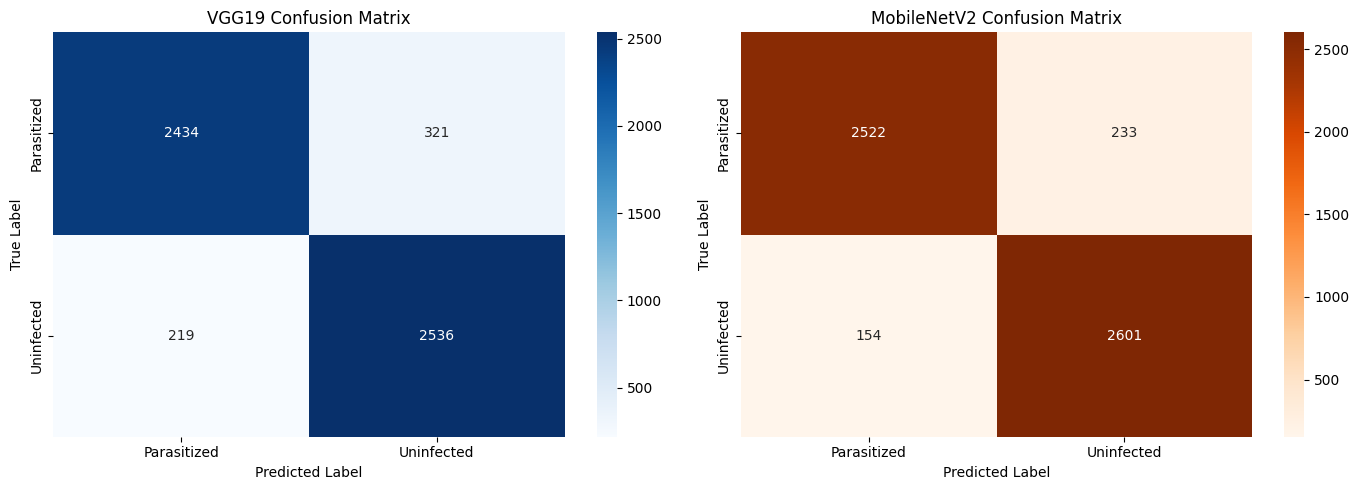

In [ ]:
print("Generating predictions on validation dataset...")

# Reset generator to ensure correct ordering of labels
val_generator.reset()
y_true = val_generator.classes  # Real ground truth labels (0: Parasitized, 1: Uninfected)

# Predict with VGG19
start_time = time.time()
vgg19_preds_raw = vgg19_model.predict(val_generator, verbose=1)
vgg19_preds = (vgg19_preds_raw > 0.5).astype(int).flatten()

# Predict with MobileNetV2
start_time_mb = time.time()
mobilenet_preds_raw = mobilenet_model.predict(val_generator, verbose=1)
mobilenet_preds = (mobilenet_preds_raw > 0.5).astype(int).flatten()

print("\n" + "="*60)
print(" 1. MODEL COMPACTNESS (NUMBER OF PARAMETERS)")
print("="*60)
vgg_params = vgg19_model.count_params()
mb_params = mobilenet_model.count_params()
print(f"VGG19 Total Parameters:       {vgg_params:,}")
print(f"MobileNetV2 Total Parameters: {mb_params:,}")
print(f"Reduction Factor:             MobileNetV2 is {vgg_params/mb_params:.1f}x smaller!")


print("\n" + "="*60)
print(" 2. DETAILED CLASSIFICATION REPORTS")
print("="*60)

target_names = list(val_generator.class_indices.keys()) # ['Parasitized', 'Uninfected']

print("\n[VGG19 CLASSIFICATION REPORT]")
print(classification_report(y_true, vgg19_preds, target_names=target_names))

print("\n[MOBILENETV2 CLASSIFICATION REPORT]")
print(classification_report(y_true, mobilenet_preds, target_names=target_names))


cm_vgg = confusion_matrix(y_true, vgg19_preds)
cm_mb = confusion_matrix(y_true, mobilenet_preds)

# Plot side-by-side matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot VGG19 Confusion Matrix
sns.heatmap(cm_vgg, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=target_names, yticklabels=target_names)
axes[0].set_title('VGG19 Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Plot MobileNetV2 Confusion Matrix
sns.heatmap(cm_mb, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=target_names, yticklabels=target_names)
axes[1].set_title('MobileNetV2 Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()


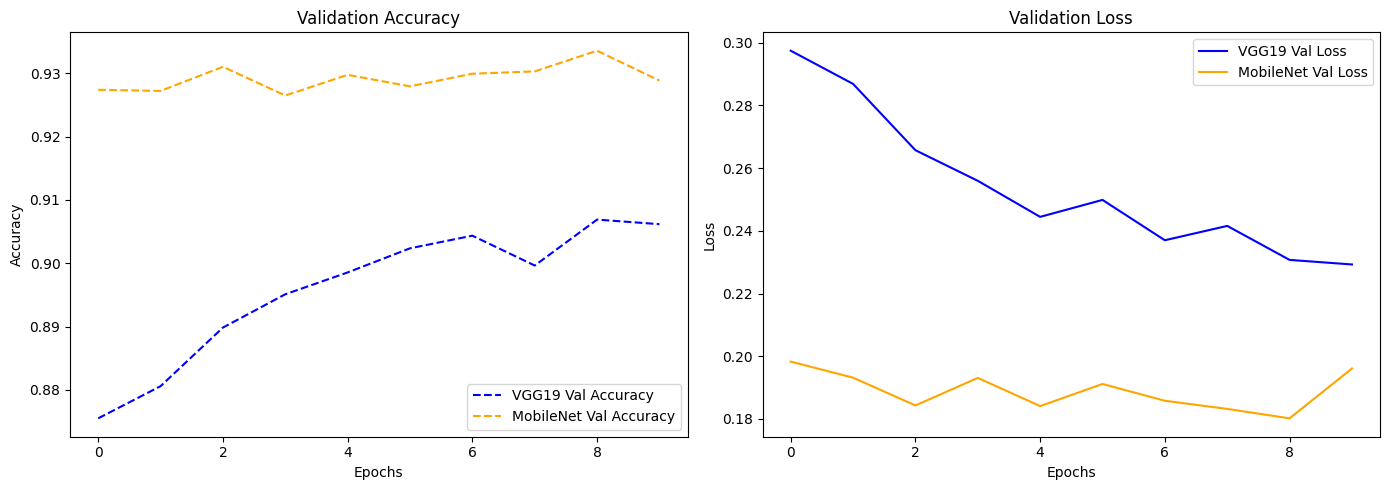

In [ ]:
plt.figure(figsize=(14, 5))
# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(vgg19_history.history['val_accuracy'], label='VGG19 Val Accuracy', color='blue', linestyle='--')
plt.plot(mobilenet_history.history['val_accuracy'], label='MobileNet Val Accuracy', color='orange', linestyle='--')
plt.title('Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(vgg19_history.history['val_loss'], label='VGG19 Val Loss', color='blue')
plt.plot(mobilenet_history.history['val_loss'], label='MobileNet Val Loss', color='orange')
plt.title('Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()